# 📊 General Text EDA: Token Length & Truncation Profiling
### Universal Diagnostic for All Text Competitions (NLU & NLG)
Tujuan: Memetakan distribusi panjang karakter, kata, dan token guna memilih `MAX_TOKEN_LENGTH` yang optimal tanpa memboroskan VRAM GPU atau memotong informasi esensial.


In [1]:
# 1. Master Config
DATA_PATH = "demo_data/train.csv"
TEXT_COL = "full_text"
MAX_LIMITS = [128, 256, 384, 512]


In [2]:
# 2. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [3]:
# 3. Load & Profiling
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")

# Character & Word count
df['char_length'] = df[TEXT_COL].astype(str).str.len()
df['word_count'] = df[TEXT_COL].astype(str).str.split().str.len()
# Approximate subword token count (~1.3x words for BPE/WordPiece)
df['approx_token_count'] = (df['word_count'] * 1.3).astype(int)

print(df[['char_length', 'word_count', 'approx_token_count']].describe())


Dataset shape: (60, 13)
       char_length  word_count  approx_token_count
count    60.000000   60.000000           60.000000
mean    464.900000   55.400000           71.700000
std      18.098319    1.509293            1.916034
min     446.000000   54.000000           70.000000
25%     448.000000   54.000000           70.000000
50%     461.500000   55.000000           71.000000
75%     479.000000   57.000000           74.000000
max     494.000000   58.000000           75.000000


In [4]:
# 4. Quantiles Table
quantiles = [0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
q_df = pd.DataFrame({
    'Quantile': [f"{int(q*100)}%" for q in quantiles],
    'Words': [int(df['word_count'].quantile(q)) for q in quantiles],
    'Approx_Tokens': [int(df['approx_token_count'].quantile(q)) for q in quantiles]
})
print("=== TOKEN LENGTH QUANTILES ===")
print(q_df.to_string(index=False))


=== TOKEN LENGTH QUANTILES ===
Quantile  Words  Approx_Tokens
     50%     55             71
     75%     57             74
     90%     57             74
     95%     58             75
     99%     58             75
    100%     58             75


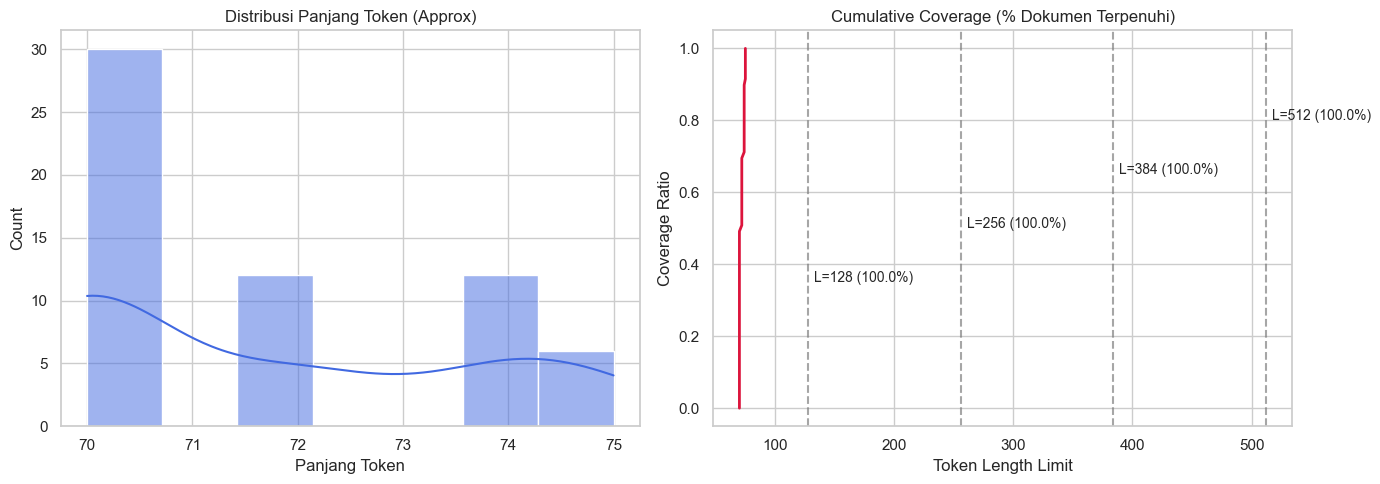

In [5]:
# 5. Visual Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['approx_token_count'], kde=True, ax=axes[0], color='royalblue')
axes[0].set_title("Distribusi Panjang Token (Approx)")
axes[0].set_xlabel("Panjang Token")

# CDF Plot
sorted_data = np.sort(df['approx_token_count'])
yvals = np.arange(len(sorted_data)) / float(len(sorted_data) - 1)
axes[1].plot(sorted_data, yvals, color='crimson', lw=2)
for lim in MAX_LIMITS:
    pct_covered = (df['approx_token_count'] <= lim).mean() * 100
    axes[1].axvline(lim, color='gray', linestyle='--', alpha=0.7)
    axes[1].text(lim + 5, 0.2 + 0.15*(lim//128), f"L={lim} ({pct_covered:.1f}%)", fontsize=10)

axes[1].set_title("Cumulative Coverage (% Dokumen Terpenuhi)")
axes[1].set_xlabel("Token Length Limit")
axes[1].set_ylabel("Coverage Ratio")
plt.tight_layout()
plt.show()


In [6]:
# 6. Truncation Strategy Demonstration
def head_tail_truncate(text: str, head_words: int = 64, tail_words: int = 192) -> str:
    words = text.split()
    if len(words) <= head_words + tail_words:
        return text
    return " ".join(words[:head_words]) + " [...] " + " ".join(words[-tail_words:])

sample_text = df[TEXT_COL].iloc[0]
print("Sample Original Word Count:", len(sample_text.split()))
truncated_sample = head_tail_truncate(sample_text, 10, 20)
print("Truncated Sample Preview:\n", truncated_sample)


Sample Original Word Count: 58
Truncated Sample Preview:
 The rapid advancement of environment has fundamentally altered human civilization. [...] education and balanced regulatory frameworks provide optimal long-term outcomes. Consequently, multi-stakeholder collaboration remains vital to ensure sustainable progress and equity.


### 📋 Master Decision Matrix (Token Length):
1. **Jika 95% dokumen $\le 256$ token:** Gunakan `MAX_TOKEN_LENGTH = 256` dan naikkan `BATCH_SIZE = 16` untuk akselerasi pelatihan.
2. **Jika 5%–20% dokumen $> 512$ token:** Jangan potong hanya dari depan! Terapkan **Head + Tail Truncation** (misal: 128 kata awal + 384 kata akhir) karena esai dan artikel sering menaruh kesimpulan di paragraf akhir.
3. **Jika > 50% dokumen $> 512$ token:** Gunakan Long-Context Transformer (Longformer / BigBird) atau arsitektur Hierarchical Attention / Chunking.
